In [ ]:
pip install pandas scikit-learn matplotlib fredapi

In [ ]:
from fredapi import Fred
import pandas as pd

fred = Fred(api_key='549cdf8937a3fc267b769e750fad2b6a')

series = {
    'unemployment':   'UNRATE',
    'job_openings':   'JTSJOL',
    'cpi':            'CPIAUCSL',
    'gdp_growth':     'A191RL1Q225SBEA',
    'lfpr':           'CIVPART',
    'avg_wages':      'CES0500000003',
    'yield_spread':   'T10Y2Y',
    'initial_claims': 'ICSA',
    'pce':            'PCE',
}

df = pd.DataFrame({
    name: fred.get_series(code)
    for name, code in series.items()
}).resample('MS').last().dropna()

print(df.shape)
print(df.tail())

(79, 9)
            unemployment  job_openings      cpi  gdp_growth  lfpr  avg_wages  \
2024-10-01           4.1        7379.0  315.631         1.9  62.5      35.46   
2025-01-01           4.0        7431.0  318.961        -0.6  62.6      35.84   
2025-04-01           4.2        7098.0  320.302         3.8  62.6      36.12   
2025-07-01           4.3        7089.0  322.169         4.4  62.2      36.47   
2026-01-01           4.3        7240.0  326.588         2.0  62.1      37.15   

            yield_spread  initial_claims      pce  
2024-10-01          0.12        219000.0  20226.0  
2025-01-01          0.36        212000.0  20462.2  
2025-04-01          0.57        239000.0  20746.4  
2025-07-01          0.43        219000.0  21007.3  
2026-01-01          0.74        230000.0  21525.5  


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

features = [
    'job_openings', 'cpi', 'gdp_growth',
    'lfpr', 'avg_wages', 'yield_spread',
    'initial_claims', 'pce'
]

X = df[features]
y = df['unemployment']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(pX_train, y_train)

preds = model.predict(X_test)
mae = mean_absolute_error(y_test, preds)
print(f'MAE: {mae:.2f}%')

MAE: 0.25%


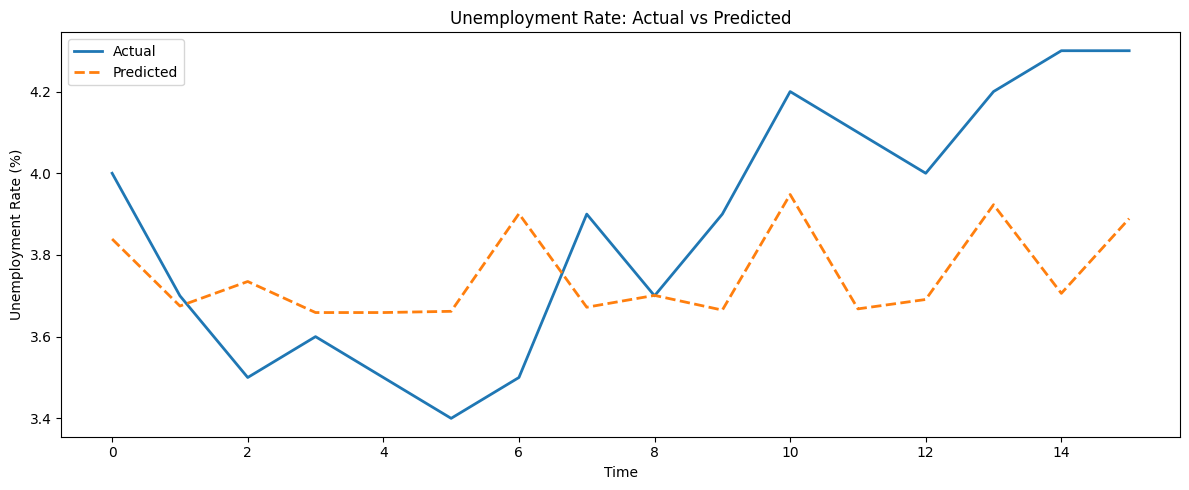

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(y_test.values, label='Actual', linewidth=2)
plt.plot(preds, label='Predicted', linestyle='--', linewidth=2)
plt.title('Unemployment Rate: Actual vs Predicted')
plt.xlabel('Time')
plt.ylabel('Unemployment Rate (%)')
plt.legend()
plt.tight_layout()
plt.savefig('results.png', dpi=150)
plt.show()